# QAF-Net · NB4 — TinyML export, deployment benchmarks, Grad-CAM, paper figures

**Accelerator: None (CPU). Internet: Off.** Latency must be measured on CPU anyway — a GPU number is
meaningless as an edge-deployment proxy.

**Attach:** the `qafnet nb1` notebook **and** your `qafnet-results` dataset (every run's
`results_*.csv`, `.tflite` and `.weights.h5` files).

Produces every figure and deployment number the paper needs:
`fig_weights.png` · `fig_confusion.png` · `fig_gradcam.png` · `fig_tradeoff.png` · `deploy.csv`

In [1]:
SMOKE_TEST = True
IMG, BATCH = 128, 32
# Primary setup after NB1's audit: 4 classes, every real site a client. Deduplication left SARTAJ
# with only 235 tumour images, so a 3-class, 3-site federation no longer exists; Br35H joins through
# the superset loss instead. Why: docs/01-research-design.md, section 3.
N_CLASSES     = 4               # glioma, meningioma, pituitary, notumor
CLASSES_USED  = (0, 1, 2, 3)
EXCLUDE       = ()              # every client site takes part
ALLOW_PARTIAL = True            # Br35H's "tumour, subtype unknown" images train via the superset loss
FOLD  = "PMRAM"
SEED  = 0
MODEL = "mobilenet"

## Shared core

_Inlined from `src/fedtiny/core.py` by `tools/build_notebooks.py`. Edit the source file, not this cell._

In [2]:
# QAF-Net core — shared by NB2/NB3/NB4.
# tools/build_notebooks.py inlines this file wherever a notebook has `# %%INCLUDE core`,
# so this is the single source of truth. Edit here, never in a notebook copy.

import os, io, json, time, math, random, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report)

CLASSES = ["glioma", "meningioma", "pituitary", "notumor"]
AUTOTUNE = tf.data.AUTOTUNE


# ---------------------------------------------------------------- reproducibility
def set_seed(s):
    os.environ["PYTHONHASHSEED"] = str(s)
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)


# ---------------------------------------------------------------- data
def load_prepared(npz_path):
    """Load NB1's output. Returns a dict of parallel arrays."""
    z = np.load(npz_path, allow_pickle=True)
    d = dict(images=z["images"], labels=z["labels"].astype(np.int32),
             partial=z["partial"].astype(np.int32), site=z["site"].astype(str),
             group=z["group"].astype(str), store=int(z["store"][0]))
    print(f"loaded {len(d['images'])} images @ {d['store']}px  sites={sorted(set(d['site']))}")
    if "smoke_test" in z.files and bool(z["smoke_test"][0]):
        print("!! WARNING: this is NB1's SMOKE_TEST output (~200 images per site). Fine for a "
              "smoke test, but re-commit NB1 with SMOKE_TEST = False before any real run.")
    if "dedup" in z.files and not bool(z["dedup"][0]):
        print("!! NOTE: NB1 ran with DEDUP = False, so cross-site duplicates are INCLUDED. "
              "Use this only for the C1 leakage ablation.")
    return d


def label_sets(labels, partial, n_classes):
    """Multi-hot allowed-class matrix. Singleton normally; {glioma,men,pit} for partial labels."""
    Y = np.zeros((len(labels), n_classes), np.float32)
    for i, (l, p) in enumerate(zip(labels, partial)):
        if p:
            Y[i, :3] = 1.0                      # tumour of unspecified subtype
        else:
            Y[i, l] = 1.0
    return Y


def loso_split(data, held_out_site, classes_used=(0, 1, 2), val_frac=0.15, seed=0,
               exclude_sites=(), allow_partial=False):
    """Leave-One-Site-Out. Returns (clients, test_idx).

    `clients` is a list of (site_name, train_idx, val_idx). Splits are grouped by patient where
    patient IDs exist, so slices from one patient never straddle train and val.

    `allow_partial=True` admits set-valued labels (Br35H's tumour-of-unknown-subtype images) to
    training through the superset loss, as the primary 4-class setup does. With False, those
    clients are left out entirely.

    Partial-label samples never enter a val or test split under any setting: you cannot score a
    prediction against a label you do not know.
    """
    rng = np.random.RandomState(seed)
    keep_cls = set(classes_used)
    labelled = np.array([l in keep_cls for l in data["labels"]]) & (data["partial"] == 0)
    usable = labelled | ((data["partial"] == 1) if allow_partial else False)

    test_idx = np.where(labelled & (data["site"] == held_out_site))[0]

    clients = []
    for s in sorted(set(data["site"])):
        if s == held_out_site or s in exclude_sites:
            continue
        idx = np.where(usable & (data["site"] == s))[0]
        if len(idx) < 50:
            print(f"  (skipping {s}: only {len(idx)} usable images)")
            continue
        groups = data["group"][idx]
        uniq = np.unique(groups); rng.shuffle(uniq)
        n_val = max(1, int(len(uniq) * val_frac))
        val_g = set(uniq[:n_val])
        is_val = np.array([g in val_g for g in groups]) & (data["partial"][idx] == 0)
        clients.append((s, idx[~is_val], idx[is_val]))

    print(f"LOSO held-out={held_out_site}  test={len(test_idx)}")
    for s, tr, va in clients:
        npart = int(data["partial"][tr].sum())
        print(f"  client {s:8s} train={len(tr):5d} (partial={npart:4d}) val={len(va):4d} "
              f"groups={len(set(data['group'][tr]))}")
    return clients, test_idx


def make_ds(data, idx, n_classes, img=128, batch=32, train=False, shuffle=True, seed=0):
    """tf.data pipeline. Stored images are (S,S) uint8 grayscale; models want (img,img,3) float."""
    X = data["images"][idx]
    Y = label_sets(data["labels"][idx], data["partial"][idx], n_classes)
    ds = tf.data.Dataset.from_tensor_slices((X, Y))
    if train and shuffle:
        ds = ds.shuffle(min(len(idx), 4096), seed=seed, reshuffle_each_iteration=True)

    S = data["store"]

    def prep(x, y):
        x = tf.cast(x, tf.float32)[..., None]
        if train:
            x = tf.image.random_crop(x, [img, img, 1])        # translation jitter from S -> img
            # PMRAM slices are stored rotated by +/-90 degrees relative to the other sites (NB1's
            # sample grid). Random quarter turns plus the flip below cover all eight orientations,
            # so no site's export convention can become a shortcut.
            x = tf.image.rot90(x, k=tf.random.uniform([], 0, 4, dtype=tf.int32))
            x = tf.image.random_flip_left_right(x)
            x = tf.image.random_brightness(x, 20.0)
            x = tf.image.random_contrast(x, 0.85, 1.15)
        else:
            off = (S - img) // 2
            x = tf.image.crop_to_bounding_box(x, off, off, img, img)
        x = tf.clip_by_value(x, 0.0, 255.0) / 127.5 - 1.0      # MobileNetV2 input range
        x = tf.repeat(x, 3, axis=-1)
        return x, y

    return ds.map(prep, num_parallel_calls=AUTOTUNE).batch(batch).prefetch(AUTOTUNE)


# ---------------------------------------------------------------- models
def build_mobilenet(n_classes, img=128, alpha=0.35, dropout=0.3, pretrained=True):
    """Built on `base.output` rather than `base(inp)` so the graph stays FLAT.

    Wrapping the backbone as a nested submodel would put its conv layers in a separate graph,
    which breaks Grad-CAM (`keras.Model(model.inputs, [conv.output, model.output])` raises a
    disconnected-graph error) and complicates weight bookkeeping for no benefit.
    """
    try:
        base = keras.applications.MobileNetV2(input_shape=(img, img, 3), alpha=alpha,
                                              include_top=False,
                                              weights="imagenet" if pretrained else None)
    except Exception as e:
        # Keras fetches the ImageNet weights from the internet on first use.
        if pretrained and any(s in str(e) for s in ("URL fetch", "resolution", "urlopen",
                                                     "unreachable", "Connection", "HTTP Error")):
            raise RuntimeError(
                "MobileNetV2 could not download its ImageNet weights. Turn Internet ON for this "
                "notebook (right panel -> Settings -> Internet) and run again.") from e
        raise
    base.trainable = True
    x = keras.layers.GlobalAveragePooling2D()(base.output)
    x = keras.layers.Dropout(dropout)(x)
    out = keras.layers.Dense(n_classes, name="head")(x)        # logits, no softmax
    return keras.Model(base.input, out, name=f"mnv2_a{alpha}_{img}")


def build_tinybtnet(n_classes, img=128, w=16, dropout=0.3):
    """~0.18 M params. Sub-200 KB once INT8-quantized — the MCU regime."""
    def blk(x, f, s=1):
        x = keras.layers.SeparableConv2D(f, 3, strides=s, padding="same", use_bias=False)(x)
        x = keras.layers.BatchNormalization()(x)
        return keras.layers.ReLU(6.0)(x)

    inp = keras.Input((img, img, 3))
    x = keras.layers.Conv2D(w, 3, strides=2, padding="same", use_bias=False)(inp)
    x = keras.layers.BatchNormalization()(x); x = keras.layers.ReLU(6.0)(x)
    for f, s in [(w*2, 2), (w*2, 1), (w*4, 2), (w*4, 1), (w*8, 2), (w*8, 1), (w*12, 2)]:
        x = blk(x, f, s)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(dropout)(x)
    out = keras.layers.Dense(n_classes, name="head")(x)
    return keras.Model(inp, out, name=f"tinybtnet_w{w}_{img}")


def build_model(name, n_classes, img=128, pretrained=True):
    """`pretrained=False` skips the ImageNet download. Use it when a checkpoint overwrites every
    weight anyway (NB4), so that notebook runs with Internet off."""
    return {"mobilenet": lambda: build_mobilenet(n_classes, img, pretrained=pretrained),
            "tinybtnet": lambda: build_tinybtnet(n_classes, img)}[name]()


# ---------------------------------------------------------------- variable bookkeeping
def _iter_layers(m):
    for l in m.layers:
        if hasattr(l, "layers"):
            yield from _iter_layers(l)
        else:
            yield l


def bn_indices(model):
    """Positions in model.get_weights() belonging to BatchNorm.

    Matched by object identity, not by name or index arithmetic — nested submodels (MobileNetV2)
    make positional guessing unreliable.
    """
    ids = set()
    for l in _iter_layers(model):
        if isinstance(l, keras.layers.BatchNormalization):
            ids.update(id(v) for v in l.weights)
    return [i for i, v in enumerate(model.weights) if id(v) in ids]


def quant_targets(model):
    """{id(kernel_variable): reduction_axes} for conv/dense kernels.

    Axes match TFLite's per-output-channel scheme: last axis for conv/dense, axis 2 for depthwise
    (whose output channels live on the input-channel dimension).
    """
    out = {}
    for l in _iter_layers(model):
        k = getattr(l, "kernel", None)
        if k is None:
            k = getattr(l, "depthwise_kernel", None)
        if k is None or len(k.shape) < 2:
            continue
        if isinstance(l, keras.layers.DepthwiseConv2D) or k is getattr(l, "depthwise_kernel", None):
            axes = [0, 1, 3]                             # depthwise: channels live on axis 2
        else:
            axes = list(range(len(k.shape) - 1))
        out[id(k)] = axes
        pw = getattr(l, "pointwise_kernel", None)          # SeparableConv2D has two kernels
        if pw is not None:
            out[id(pw)] = list(range(len(pw.shape) - 1))
    return out


def fake_quant(w, axes, bits=8):
    """Per-channel symmetric INT8 round-trip. Differentiable target is stop_gradiented by caller."""
    qmax = float(2 ** (bits - 1) - 1)
    s = tf.reduce_max(tf.abs(w), axis=axes, keepdims=True) / qmax
    s = tf.maximum(s, 1e-12)
    return tf.round(w / s) * s


# ---------------------------------------------------------------- losses
def superset_ce(y_sets, logits):
    """-log sum_{c in S} p_c. Reduces to standard cross-entropy when |S| = 1."""
    logp = tf.nn.log_softmax(logits)
    masked = tf.where(y_sets > 0, logp, tf.fill(tf.shape(logp), -1e9))
    return -tf.reduce_logsumexp(masked, axis=-1)


# ---------------------------------------------------------------- local training
class LocalTrainer:
    """One client's local optimizer.

        L = superset_CE + (mu/2)||w - w_global||^2 + lam * mean_j (w_j - Q(w_j))^2

    mu  > 0  -> FedProx drift control
    lam > 0  -> QAF-Net quantization-aware term (contribution C2)

    The `tf.function` is traced **once** and reused across every client and every round; anchors
    live in `tf.Variable`s that get reassigned. Rebuilding it per call would retrace the graph
    hundreds of times per experiment and dominate the runtime.
    """

    def __init__(self, model, lr, mu=0.0, lam=0.0):
        self.model, self.mu, self.lam = model, mu, lam
        self.opt = keras.optimizers.Adam(lr)
        self.tvars = model.trainable_variables
        self.by_id = {id(v): i for i, v in enumerate(model.weights)}

        qmap = quant_targets(model) if lam > 0 else {}
        self.qaxes = [qmap.get(id(v)) for v in self.tvars]
        self.anchors = ([tf.Variable(tf.zeros_like(v), trainable=False) for v in self.tvars]
                        if mu > 0 else None)
        try:
            self.opt.build(self.tvars)          # Keras 3; older versions build lazily
        except Exception:
            pass
        self._step = tf.function(self._step_impl, reduce_retracing=True)

    def _step_impl(self, x, y):
        with tf.GradientTape() as tape:
            logits = self.model(x, training=True)
            loss = tf.reduce_mean(superset_ce(y, logits))
            if self.anchors is not None:
                loss += (self.mu / 2.0) * tf.add_n(
                    [tf.reduce_sum(tf.square(v - a)) for v, a in zip(self.tvars, self.anchors)])
            if self.lam > 0:
                terms = [tf.reduce_mean(tf.square(v - tf.stop_gradient(fake_quant(v, ax))))
                         for v, ax in zip(self.tvars, self.qaxes) if ax is not None]
                if terms:
                    loss += self.lam * tf.add_n(terms)
        self.opt.apply_gradients(zip(tape.gradient(loss, self.tvars), self.tvars))
        return loss

    def set_anchor(self, global_w):
        if self.anchors is None:
            return
        for a, v in zip(self.anchors, self.tvars):
            a.assign(global_w[self.by_id[id(v)]])

    def reset_optimizer(self):
        """FL clients are stateless — Adam moments must not carry from one client to the next."""
        # Reset ONLY Adam's moment slots. Keras 3 keeps the learning rate itself among
        # `optimizer.variables`; zeroing those set lr = 0, so nothing trained.
        slots = []
        for attr in ("_momentums", "_velocities", "_velocity_hats"):
            slots += list(getattr(self.opt, attr, None) or [])
        if not slots:
            vs = getattr(self.opt, "variables", None)
            vs = vs() if callable(vs) else (vs or [])
            slots = [v for v in vs
                     if not any(k in v.name for k in ("learning_rate", "iteration"))]
        for v in slots:
            v.assign(tf.zeros_like(v))
        if hasattr(self.opt, "iterations"):
            self.opt.iterations.assign(0)
        lr = float(np.asarray(self.opt.learning_rate))
        assert lr > 0, f"learning rate is {lr} after optimizer reset"

    def run(self, ds, epochs, verbose=0):
        hist = []
        for e in range(epochs):
            tot = n = 0.0
            for x, y in ds:
                tot += float(self._step(x, y)); n += 1
            hist.append(tot / max(n, 1))
            if verbose:
                print(f"    epoch {e+1}/{epochs} loss={hist[-1]:.4f}")
        return hist


# ---------------------------------------------------------------- aggregation
def fedavg(client_ws, sizes, skip=()):
    """Size-weighted parameter average. Indices in `skip` keep client-0's values untouched
    (used for site-local BN — those are restored per client anyway)."""
    w = np.asarray(sizes, np.float64); w /= w.sum()
    skip = set(skip)
    out = []
    for j in range(len(client_ws[0])):
        if j in skip:
            out.append(np.array(client_ws[0][j]))
        else:
            out.append(sum(wi * np.asarray(cw[j]) for wi, cw in zip(w, client_ws)))
    return out


def bn_average(client_ws, sizes, bn_idx):
    """Size-weighted average of BN parameters only — the default global BN for an unseen site."""
    w = np.asarray(sizes, np.float64); w /= w.sum()
    return {j: sum(wi * np.asarray(cw[j]) for wi, cw in zip(w, client_ws)) for j in bn_idx}


def bn_recalibrate(model, ds, steps=100):
    """Re-estimate BN statistics on the TARGET site using unlabeled forward passes only.

    No labels, no gradients, no data leaves the site — this is the deployment-time calibration
    step behind contribution C3.
    """
    saved = [(l, float(l.momentum)) for l in _iter_layers(model)
             if isinstance(l, keras.layers.BatchNormalization)]
    for l, _ in saved:
        l.momentum = 0.9
    n = 0
    for x, _ in ds:
        model(x, training=True)                 # updates moving_mean / moving_variance only
        n += 1
        if n >= steps:
            break
    for l, m in saved:
        l.momentum = m
    return n


# ---------------------------------------------------------------- evaluation
def _metrics(yt, prob, n_classes):
    """Scores for one evaluation: `yt` true class ids, `prob` softmax rows.

    macro-F1 averages over the classes present in the test set, so a 4-class model tested on a
    tumour-only site is not charged an undefined F1 for "notumor"; predicting "notumor" there still
    costs recall on the true classes. `acc_sub` scores tumour images on the three tumour logits
    alone (subtype accuracy). `tumor_missed` is the share of tumour images called "notumor".
    """
    yt = np.asarray(yt)
    yp = prob.argmax(1)
    present = sorted(set(yt.tolist()))
    m = dict(acc=float(accuracy_score(yt, yp)),
             macro_f1=float(f1_score(yt, yp, labels=present, average="macro", zero_division=0)))
    try:
        m["auc"] = float(roc_auc_score(np.eye(n_classes)[yt][:, present], prob[:, present],
                                       average="macro", multi_class="ovr"))
    except Exception:
        m["auc"] = float("nan")
    tumour = yt < 3
    if tumour.any():
        m["acc_sub"] = float((prob[tumour, :3].argmax(1) == yt[tumour]).mean())
        m["tumor_missed"] = float((yp[tumour] == 3).mean()) if n_classes > 3 else 0.0
    else:
        m["acc_sub"] = m["tumor_missed"] = float("nan")
    m["cm"] = confusion_matrix(yt, yp, labels=list(range(n_classes))).tolist()
    return m


def evaluate(model, ds, n_classes, name=""):
    logits, ys = [], []
    for x, y in ds:
        logits.append(model(x, training=False).numpy()); ys.append(y.numpy())
    logits = np.concatenate(logits); Y = np.concatenate(ys)
    prob = tf.nn.softmax(logits).numpy()
    yt = Y.argmax(1)                                    # test sets are always singleton-labelled
    m = _metrics(yt, prob, n_classes)
    m["report"] = classification_report(yt, prob.argmax(1), labels=list(range(n_classes)),
                                        target_names=CLASSES[:n_classes],
                                        output_dict=True, zero_division=0)
    if name:
        print(f"  {name:26s} acc={m['acc']:.4f} subtype={m['acc_sub']:.4f} "
              f"macroF1={m['macro_f1']:.4f} auc={m['auc']:.4f}")
    return m


# ---------------------------------------------------------------- TinyML export
def to_tflite_int8(model, rep_ds, n_batches=100, workdir="/kaggle/working/_export"):
    """Full-integer INT8 conversion — int8 in, int8 out, MCU-deployable."""
    def rep_gen():
        for i, (x, _) in enumerate(rep_ds):
            if i >= n_batches:
                break
            yield [tf.cast(x, tf.float32)]

    def _cfg(c):
        c.optimizations = [tf.lite.Optimize.DEFAULT]
        c.representative_dataset = rep_gen
        c.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
        c.inference_input_type = tf.int8
        c.inference_output_type = tf.int8
        return c

    try:
        return _cfg(tf.lite.TFLiteConverter.from_keras_model(model)).convert()
    except Exception as e:
        # Keras 3 sometimes needs the SavedModel route.
        print(f"  from_keras_model failed ({type(e).__name__}); using SavedModel export")
        os.makedirs(workdir, exist_ok=True)
        p = os.path.join(workdir, model.name)
        if hasattr(model, "export"):
            model.export(p)                     # Keras 3
        else:
            tf.saved_model.save(model, p)       # Keras 2
        return _cfg(tf.lite.TFLiteConverter.from_saved_model(p)).convert()


def tflite_interpreter(tflite_bytes):
    """TFLite interpreter from LiteRT when installed, otherwise tf.lite.

    tf.lite.Interpreter is deprecated and scheduled for removal from TensorFlow. It still exists in
    TF 2.20, which Kaggle runs today; preferring ai_edge_litert keeps these notebooks working when
    Kaggle's image moves past it.
    """
    try:
        from ai_edge_litert.interpreter import Interpreter
    except ImportError:
        Interpreter = getattr(getattr(tf, "lite", None), "Interpreter", None)
        if Interpreter is None:
            raise ImportError("This TensorFlow has no tf.lite.Interpreter. Turn Settings -> Internet "
                              "on and run:  !pip install ai-edge-litert")
    return Interpreter(model_content=tflite_bytes)


def eval_tflite(tflite_bytes, ds, n_classes, name=""):
    """Evaluate the quantized model, honouring the interpreter's own input/output quant params."""
    it = tflite_interpreter(tflite_bytes)
    it.allocate_tensors()
    ind, outd = it.get_input_details()[0], it.get_output_details()[0]
    is_, iz = ind["quantization"]
    os_, oz = outd["quantization"]
    # A zero scale means the tensor came back unquantized; treat it as identity rather than
    # dividing by zero and silently producing garbage predictions.
    if is_ == 0: is_, iz = 1.0, 0
    if os_ == 0: os_, oz = 1.0, 0

    yt, yp, probs, lat = [], [], [], []
    for x, y in ds:
        for xi, yi in zip(x.numpy(), y.numpy()):
            q = np.clip(np.round(xi / is_ + iz), -128, 127).astype(ind["dtype"])[None]
            it.set_tensor(ind["index"], q)
            t0 = time.perf_counter(); it.invoke(); lat.append((time.perf_counter() - t0) * 1e3)
            o = it.get_tensor(outd["index"])[0].astype(np.float32)
            logits = (o - oz) * os_
            p = np.exp(logits - logits.max()); p /= p.sum()
            probs.append(p); yp.append(int(p.argmax())); yt.append(int(yi.argmax()))

    m = _metrics(np.array(yt), np.stack(probs), n_classes)
    m.update(latency_ms_mean=float(np.mean(lat)), latency_ms_p95=float(np.percentile(lat, 95)),
             size_kb=len(tflite_bytes) / 1024.0)
    if name:
        print(f"  {name:26s} acc={m['acc']:.4f} subtype={m['acc_sub']:.4f} macroF1={m['macro_f1']:.4f} "
              f"size={m['size_kb']:.0f}KB lat={m['latency_ms_mean']:.2f}ms")
    return m


def model_cost(model):
    """Parameter count and multiply-accumulate estimate for conv/dense layers."""
    macs = 0
    for l in _iter_layers(model):
        try:
            osh = l.output.shape
        except Exception:
            continue
        if isinstance(l, keras.layers.DepthwiseConv2D):
            dk = getattr(l, "depthwise_kernel", None)
            if dk is None:
                dk = l.kernel                            # Keras 3 renamed depthwise_kernel to kernel
            kh, kw, cin, mult = dk.shape
            macs += int(osh[1]) * int(osh[2]) * int(kh) * int(kw) * int(cin) * int(mult)
        elif isinstance(l, keras.layers.SeparableConv2D):
            kh, kw, cin, mult = l.depthwise_kernel.shape
            macs += int(osh[1]) * int(osh[2]) * (int(kh)*int(kw)*int(cin)*int(mult)
                                                 + int(cin)*int(mult)*int(osh[3]))
        elif isinstance(l, keras.layers.Conv2D):
            kh, kw, cin, cout = l.kernel.shape
            macs += int(osh[1]) * int(osh[2]) * int(kh) * int(kw) * int(cin) * int(cout)
        elif isinstance(l, keras.layers.Dense):
            macs += int(l.kernel.shape[0]) * int(l.kernel.shape[1])
    return dict(params=int(model.count_params()), macs=int(macs))


# ---------------------------------------------------------------- results log
def log_result(path, **row):
    """Add one run to results.csv under a single consistent header.

    Notebooks log different fields (local-only runs have no internal-validation numbers), so rows
    are merged by column name. Appending blindly would put values under the wrong headers.
    """
    row = {k: (json.dumps(v) if isinstance(v, (list, dict)) else v) for k, v in row.items()}
    df = pd.DataFrame([row])
    if os.path.exists(path):
        df = pd.concat([pd.read_csv(path), df], ignore_index=True, sort=False)
    df.to_csv(path, index=False)
    return df


In [3]:
import glob
import matplotlib.pyplot as plt
set_seed(SEED)
print("TF", tf.__version__)

npz = (glob.glob("/kaggle/input/**/qafnet_data.npz", recursive=True) or [None])[0]
assert npz, "qafnet_data.npz not found. + Add Input -> Notebooks -> qafnet nb1"
data = load_prepared(npz)
clients, test_idx = loso_split(data, FOLD, CLASSES_USED, seed=SEED,
                              exclude_sites=EXCLUDE, allow_partial=ALLOW_PARTIAL)
test_ds = make_ds(data, test_idx, N_CLASSES, IMG, BATCH)
rep_ds  = make_ds(data, np.concatenate([c[1] for c in clients]), N_CLASSES, IMG, BATCH,
                  train=True, seed=SEED)

TF 2.20.0
loaded 11528 images @ 144px  sites=[np.str_('BR35H'), np.str_('CHENG'), np.str_('PMRAM'), np.str_('SARTAJ')]
LOSO held-out=PMRAM  test=6012
  client BR35H    train= 1811 (partial=1275) val=  97 groups=1811
  client CHENG    train= 2632 (partial=   0) val= 432 groups=199
  client SARTAJ   train=  463 (partial=   0) val=  81 groups=463


2026-09-21 19:01:52.994511: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [4]:
# Score every artifact on ITS OWN held-out site. A model that had PMRAM as a training client
# must never be tested on PMRAM: that is in-distribution and would inflate the table.
_test_cache = {}
def test_ds_for(fold):
    if fold not in _test_cache:
        _, idx = loso_split(data, fold, CLASSES_USED, seed=SEED,
                            exclude_sites=EXCLUDE, allow_partial=ALLOW_PARTIAL)
        _test_cache[fold] = make_ds(data, idx, N_CLASSES, IMG, BATCH)
    return _test_cache[fold]

def fold_of(name):
    # NB3 names its outputs <method>_<FOLD>_s<seed>_<model>
    for f in sorted(set(data['site'])):
        if f'_{f}_' in name:
            return f
    return FOLD

## 1. Deployment envelope

`.tflite` byte size is what goes in flash. The **tensor arena** is the peak RAM the interpreter
needs, and it is usually the binding constraint on a microcontroller — an Arduino Nano 33 BLE has
1 MB flash but only **256 KB** of SRAM, so a model can fit in flash and still be undeployable.

The arena figure below is an estimate (peak concurrent input+output tensor bytes). The true
number comes from TFLite Micro's own allocator on-device; we report ours as a lower bound and say
so in the paper.

In [5]:
def arena_estimate(tflite_bytes):
    """Peak concurrent activation memory, as a lower bound on the TFLite Micro arena.

    Uses the interpreter's op list when available (a private API, hence the fallback) and
    otherwise sums the two largest non-constant tensors.
    """
    it = tflite_interpreter(tflite_bytes); it.allocate_tensors()
    det = {d["index"]: d for d in it.get_tensor_details()}

    def nbytes(d):
        if len(d["shape"]) == 0 or any(s <= 0 for s in d["shape"]):
            return 0
        return int(np.prod(d["shape"])) * np.dtype(d["dtype"]).itemsize

    try:
        ops = it._get_ops_details()
        peak = 0
        for o in ops:
            live = sum(nbytes(det[i]) for i in list(o["inputs"]) + list(o["outputs"])
                       if i in det and i >= 0)
            peak = max(peak, live)
        return peak
    except Exception:
        sizes = sorted((nbytes(d) for d in det.values()), reverse=True)
        return sum(sizes[:2])


rows = []
for path in sorted(glob.glob("/kaggle/input/**/*.tflite", recursive=True)):
    blob = open(path, "rb").read()
    name = os.path.basename(path).replace(".tflite", "")
    fold = fold_of(name)
    m = eval_tflite(blob, test_ds_for(fold), N_CLASSES, name)
    arena = arena_estimate(blob)
    rows.append(dict(artifact=name, fold=fold, size_kb=round(len(blob)/1024, 1),
                     arena_kb=round(arena/1024, 1),
                     acc=round(m["acc"], 4), acc_sub=round(m["acc_sub"], 4), macro_f1=round(m["macro_f1"], 4),
                     latency_ms=round(m["latency_ms_mean"], 3),
                     latency_p95=round(m["latency_ms_p95"], 3),
                     fits_nano33=(len(blob)/1024 < 900 and arena/1024 < 200),
                     fits_pico=(len(blob)/1024 < 1800 and arena/1024 < 220)))

deploy = pd.DataFrame(rows)
if len(deploy):
    deploy.to_csv("/kaggle/working/deploy.csv", index=False)
    print(deploy.to_string(index=False))
else:
    print("No .tflite files found — attach an NB3 output dataset.")

LOSO held-out=CHENG  test=3064
  client BR35H    train= 1811 (partial=1275) val=  97 groups=1811
  client PMRAM    train= 5111 (partial=   0) val= 901 groups=5111
  client SARTAJ   train=  463 (partial=   0) val=  81 groups=463


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


  fedavg_CHENG_s0_mobilenet  acc=0.5636 subtype=0.5636 macroF1=0.5655 size=606KB lat=1.96ms
  fedbn_CHENG_s0_mobilenet   acc=0.8913 subtype=0.8913 macroF1=0.8821 size=606KB lat=1.94ms
  fedprox_CHENG_s0_mobilenet acc=0.4047 subtype=0.4050 macroF1=0.3989 size=606KB lat=1.91ms
  qafnet_CHENG_s0_mobilenet  acc=0.7836 subtype=0.7839 macroF1=0.7789 size=606KB lat=1.92ms
  fedavg_CHENG_s1_mobilenet  acc=0.8851 subtype=0.8851 macroF1=0.8770 size=606KB lat=1.93ms
  fedbn_CHENG_s1_mobilenet   acc=0.7334 subtype=0.7334 macroF1=0.7041 size=606KB lat=1.95ms
  fedprox_CHENG_s1_mobilenet acc=0.9422 subtype=0.9422 macroF1=0.9364 size=606KB lat=1.92ms
  qafnet_CHENG_s1_mobilenet  acc=0.7882 subtype=0.7914 macroF1=0.7895 size=606KB lat=1.90ms
  fedavg_CHENG_s2_mobilenet  acc=0.8512 subtype=0.8512 macroF1=0.8512 size=606KB lat=1.89ms
  fedbn_CHENG_s2_mobilenet   acc=0.5862 subtype=0.5862 macroF1=0.4869 size=606KB lat=1.91ms
  fedprox_CHENG_s2_mobilenet acc=0.8721 subtype=0.8721 macroF1=0.8624 size=606KB

## 2. Why the method works — weight distributions ← the key figure for C2

INT8 quantization maps each channel's weights onto 256 uniformly spaced levels using one scale
factor. A **wide, heavy-tailed** distribution wastes most of those levels on empty space and
rounds the dense centre coarsely. That is one candidate mechanism for a larger FedAvg→INT8 drop,
and this figure is how you check it.

Plotted: the residual `w − Q(w)` for each method. FedAvg should show a broad residual;
QAF-Net's should be concentrated near zero, because the training objective put it there.

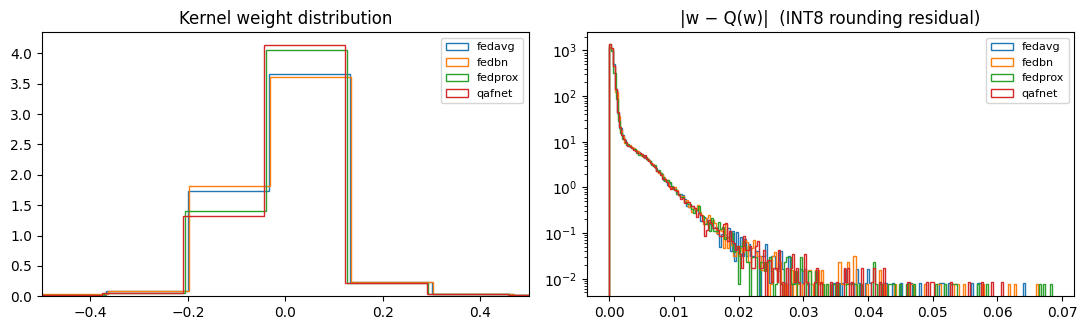

In [6]:
def kernel_weights(model):
    q = quant_targets(model)
    return np.concatenate([v.numpy().ravel() for v in model.weights if id(v) in q])

def quant_residual(model):
    q = quant_targets(model)
    res = []
    for v in model.weights:
        if id(v) in q:
            w = tf.cast(v, tf.float32)
            res.append((w - fake_quant(w, q[id(v)])).numpy().ravel())
    return np.concatenate(res)

# Reconstructing the FP32 models needs NB3's weights. If you also saved `.weights.h5` there,
# point this at them; otherwise the figure is built from whatever Keras checkpoints are attached.
# A checkpoint only loads into the architecture that produced it.
# Only the FOLD / SEED set at the top, so the figure shows one line per method (4, not 36).
ckpts = sorted(c for c in glob.glob("/kaggle/input/**/*.weights.h5", recursive=True)
               if c.endswith(f"_{FOLD}_s{SEED}_{MODEL}.weights.h5"))
if ckpts:
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
    for c in ckpts:
        m = build_model(MODEL, N_CLASSES, IMG, pretrained=False); m.load_weights(c)
        tag = os.path.basename(c).split("_")[0]
        ax[0].hist(kernel_weights(m), bins=200, density=True, histtype="step", lw=1.5, label=tag)
        ax[1].hist(np.abs(quant_residual(m)), bins=200, density=True, histtype="step",
                   lw=1.5, label=tag)
    ax[0].set_title("Kernel weight distribution"); ax[0].set_xlim(-0.5, 0.5); ax[0].legend(fontsize=8)
    ax[1].set_title("|w − Q(w)|  (INT8 rounding residual)"); ax[1].set_yscale("log")
    ax[1].legend(fontsize=8)
    plt.tight_layout(); plt.savefig("/kaggle/working/fig_weights.png", dpi=160); plt.show()
else:
    print("No .weights.h5 checkpoints attached — add `model.save_weights(...)` to NB3 to get "
          "this figure. It is worth the extra line; it is the figure that explains the result.")

## 3. Grad-CAM — does the model look at the tumour?

Answers the XAI item from your original future-scope slide, and it is the standard sanity check a
reviewer expects: a model that classifies from skull shape or scanner artefact rather than the
lesion will still score well on an internal split and fail in the clinic.

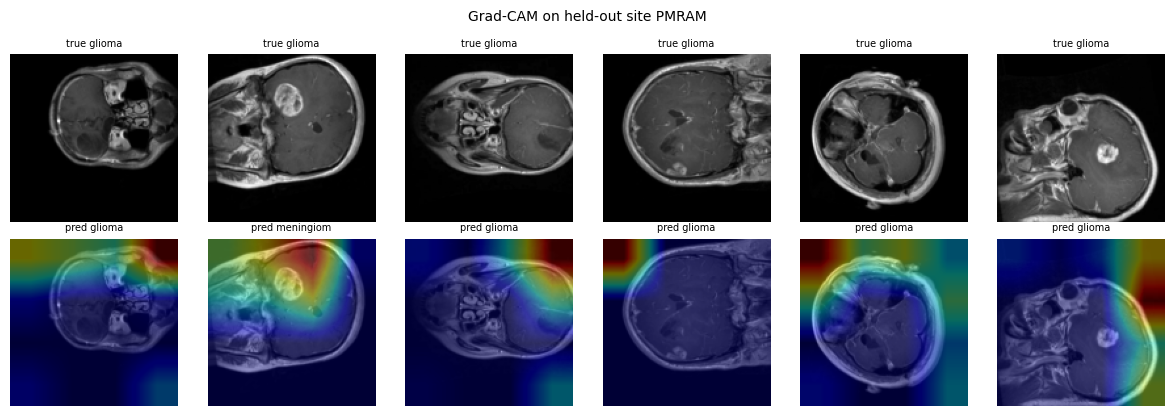

In [7]:
def gradcam(model, x, class_idx=None, last_conv=None):
    if last_conv is None:
        for l in reversed(list(_iter_layers(model))):
            if isinstance(l, keras.layers.Conv2D) and len(l.output.shape) == 4:
                last_conv = l; break
    feat = keras.Model(model.inputs, [last_conv.output, model.output])
    with tf.GradientTape() as tape:
        conv, pred = feat(x[None], training=False)
        tape.watch(conv)
        ci = int(tf.argmax(pred[0])) if class_idx is None else class_idx
        score = pred[:, ci]
    g = tape.gradient(score, conv)[0]
    cam = tf.reduce_sum(conv[0] * tf.reduce_mean(g, axis=(0, 1)), axis=-1).numpy()
    cam = np.maximum(cam, 0)
    cam = cam / (cam.max() + 1e-8)
    cam = np.array(tf.image.resize(cam[..., None], (IMG, IMG))[..., 0])
    return cam, ci

if ckpts:
    m = build_model(MODEL, N_CLASSES, IMG, pretrained=False); m.load_weights(ckpts[-1])
    cam_fold = fold_of(os.path.basename(ckpts[-1]))
    xb, yb = next(iter(test_ds_for(cam_fold)))   # its own held-out site
    n = min(6, len(xb))
    fig, ax = plt.subplots(2, n, figsize=(2.0 * n, 4.2))
    for i in range(n):
        cam, ci = gradcam(m, xb[i])
        base = (xb[i][..., 0].numpy() + 1) / 2
        ax[0, i].imshow(base, cmap="gray"); ax[0, i].axis("off")
        ax[0, i].set_title(f"true {CLASSES[int(yb[i].numpy().argmax())][:9]}", fontsize=7)
        ax[1, i].imshow(base, cmap="gray"); ax[1, i].imshow(cam, cmap="jet", alpha=0.42)
        ax[1, i].axis("off"); ax[1, i].set_title(f"pred {CLASSES[ci][:9]}", fontsize=7)
    plt.suptitle(f"Grad-CAM on held-out site {cam_fold}", fontsize=10)
    plt.tight_layout(); plt.savefig("/kaggle/working/fig_gradcam.png", dpi=160); plt.show()

## 4. Result figures from `results.csv`

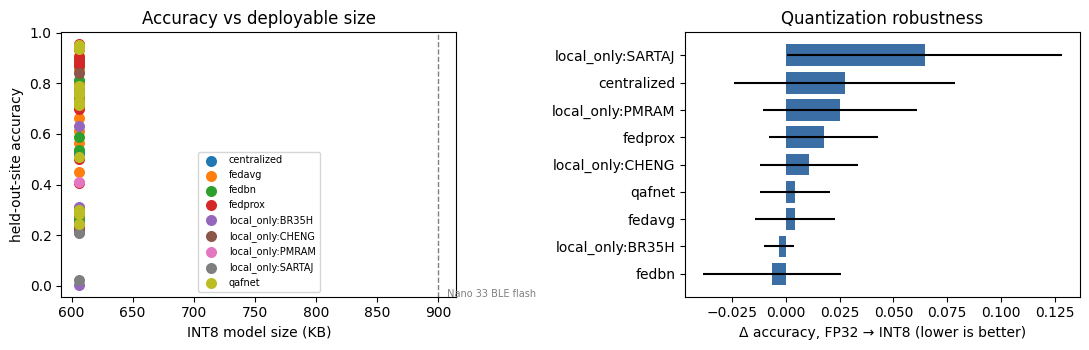

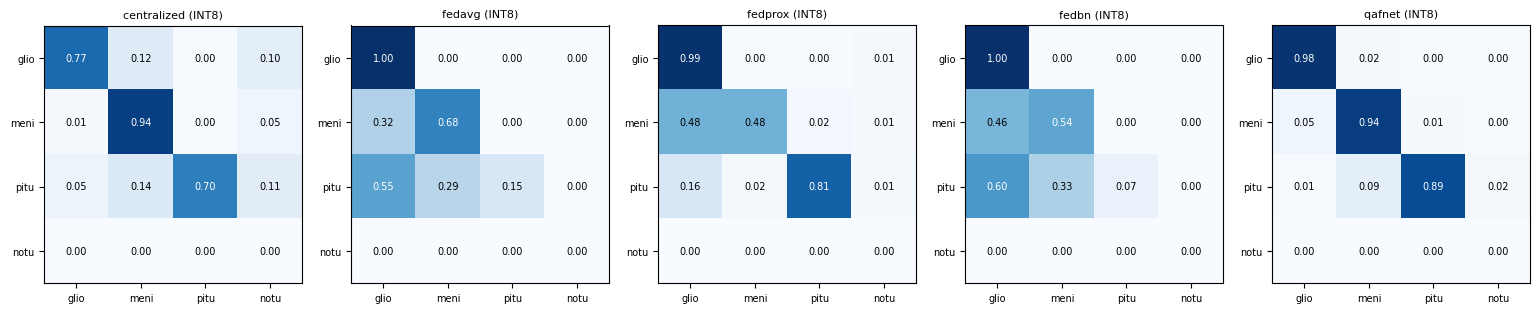

                   acc_fp32_out  acc_int8_out  dq_out   size_kb  latency_ms
method                                                                     
centralized              0.6411        0.6138  0.0273  606.3073      1.3612
fedavg                   0.5940        0.5897  0.0043  606.2969      1.3326
fedbn                    0.6239        0.6303 -0.0064  606.3125      1.3286
fedprox                  0.6385        0.6210  0.0175  606.3125      1.3103
local_only:BR35H         0.3137        0.3167 -0.0030  606.3125      1.3610
local_only:CHENG         0.5444        0.5338  0.0106  606.3125      1.3397
local_only:PMRAM         0.3534        0.3281  0.0253  606.3125      1.3615
local_only:SARTAJ        0.1806        0.1162  0.0645  606.3125      1.3807
qafnet                   0.6307        0.6264  0.0043  606.3125      1.3213


In [8]:
res = (glob.glob("/kaggle/input/**/results.csv", recursive=True)
       + glob.glob("/kaggle/working/results.csv"))
if res:
    R = pd.concat([pd.read_csv(p) for p in res], ignore_index=True)

    # (a) accuracy/size trade-off — the TinyML claim
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    for meth, g in R.groupby("method"):
        ax[0].scatter(g.size_kb, g.acc_int8_out, s=48, label=meth)
    ax[0].set_xlabel("INT8 model size (KB)"); ax[0].set_ylabel("held-out-site accuracy")
    ax[0].axvline(900, ls="--", c="gray", lw=1)
    ax[0].text(905, ax[0].get_ylim()[0], " Nano 33 BLE flash", fontsize=7, color="gray")
    ax[0].legend(fontsize=7); ax[0].set_title("Accuracy vs deployable size")

    # (b) the headline: quantization drop by method
    d = R.groupby("method").dq_out.agg(["mean", "std"]).sort_values("mean")
    ax[1].barh(d.index, d["mean"], xerr=d["std"].fillna(0), color="#3b6ea5")
    ax[1].set_xlabel("Δ accuracy, FP32 → INT8 (lower is better)")
    ax[1].set_title("Quantization robustness")
    plt.tight_layout(); plt.savefig("/kaggle/working/fig_tradeoff.png", dpi=160); plt.show()

    # (c) confusion matrices
    sub = R.dropna(subset=["cm_int8_out"]).drop_duplicates("method")
    if len(sub):
        fig, ax = plt.subplots(1, len(sub), figsize=(3.1 * len(sub), 3.1))
        for a, (_, row) in zip(np.atleast_1d(ax), sub.iterrows()):
            cm = np.array(json.loads(row.cm_int8_out), float)
            cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
            a.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
            for i in range(len(cm)):
                for j in range(len(cm)):
                    a.text(j, i, f"{cmn[i,j]:.2f}", ha="center", va="center", fontsize=7,
                           color="white" if cmn[i, j] > .5 else "black")
            a.set_xticks(range(N_CLASSES)); a.set_yticks(range(N_CLASSES))
            a.set_xticklabels([c[:4] for c in CLASSES[:N_CLASSES]], fontsize=7)
            a.set_yticklabels([c[:4] for c in CLASSES[:N_CLASSES]], fontsize=7)
            a.set_title(f"{row.method} (INT8)", fontsize=8)
        plt.tight_layout(); plt.savefig("/kaggle/working/fig_confusion.png", dpi=160); plt.show()

    print(R.groupby("method")[["acc_fp32_out", "acc_int8_out", "dq_out",
                               "size_kb", "latency_ms"]].mean().round(4).to_string())
else:
    print("No results.csv found — run NB2/NB3 first and attach their outputs.")

---
Hand over: `deploy.csv`, `results.csv`, and the four `fig_*.png` files.